In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [23]:
inflation_clean=pd.read_csv(
    "../data/processed/inflation_latam_clean.cvs"
)

In [24]:
# creamos un atabla d ela inflación promedio por pais 
avg_infaltion=(
    inflation_clean
    .groupby("country")["inflation"]
    .mean()
    .sort_values(ascending=False)
)

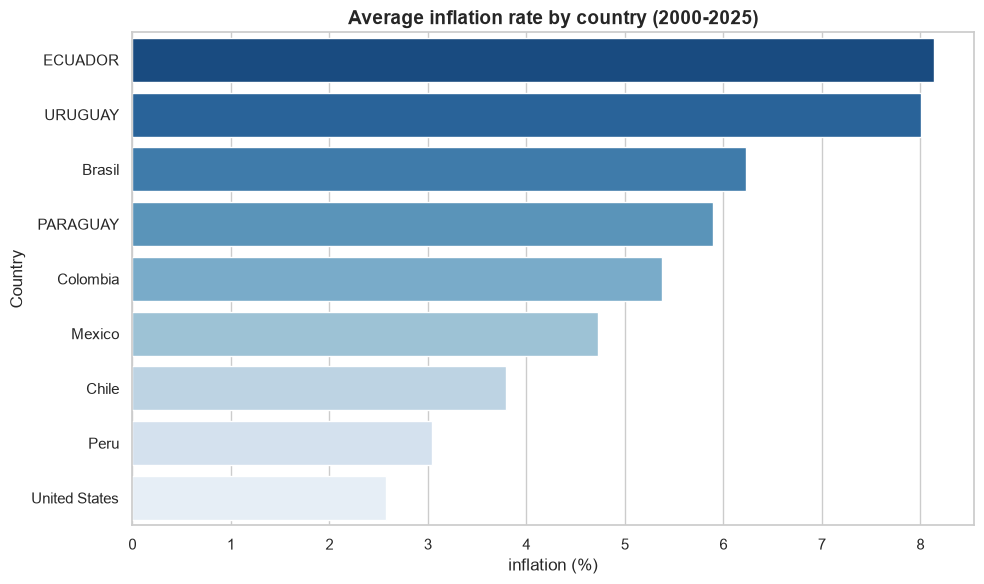

In [25]:
plt.figure(figsize=(10,6))

sns.barplot(
    x=avg_infaltion.values,
    y=avg_infaltion.index,
    hue=avg_infaltion.index,
    palette="Blues_r",
    legend=False
)

plt.title(
    "Average inflation rate by country (2000-2025)", 
    fontsize=14,
    fontweight="bold"
)

plt.xlabel('inflation (%)')
plt.ylabel("Country")

plt.tight_layout()

plt.savefig(
    "../images/avg_inflation.png",
    bbox_inches="tight",
    dpi=300
)
plt.show()

In [26]:
#grafico2 Volatilidad de la inflación por país

inflation_volatility =(
    inflation_clean
    .groupby("country")["inflation"]
    .std()
    .sort_values(ascending=False)
)

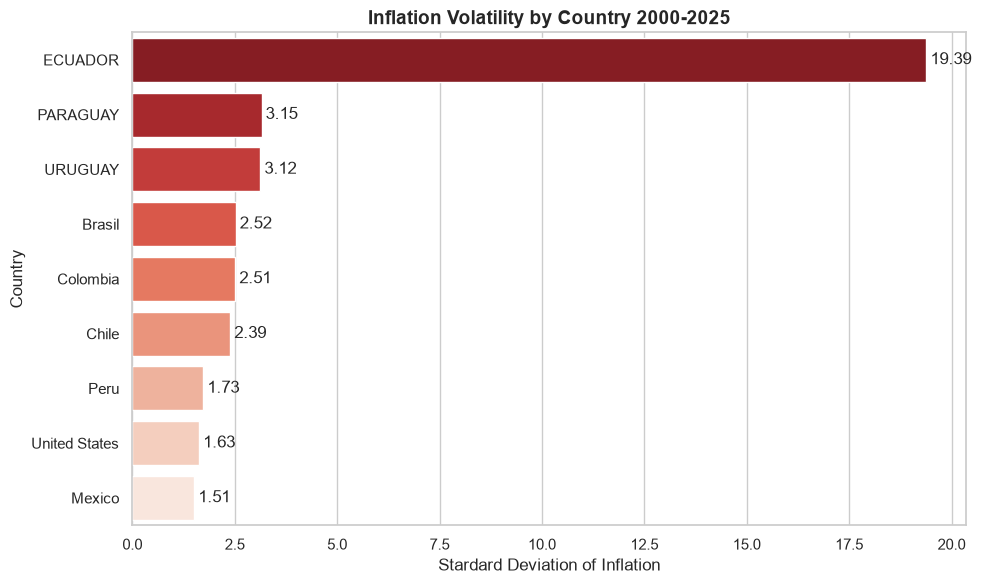

In [27]:
# Grafico

plt.figure(figsize=(10,6))

ax= sns.barplot(
    x=inflation_volatility.values,
    y=inflation_volatility.index,
    hue=inflation_volatility.index,
    palette="Reds_r",
    legend=False
)

for i, value in enumerate(inflation_volatility.values):
    ax.text(
        value +0.1,
        i,
        f"{value:.2f}",
        va="center"
    )

plt.title(
    "Inflation Volatility by Country 2000-2025", 
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Stardard Deviation of Inflation")

plt.ylabel("Country")

plt.tight_layout()
plt.savefig(
    "../images/inflation_volatility.png",
    dpi=300,
    bbox_inches="tight"
)


In [29]:
latam_data=inflation_clean[
    inflation_clean["country"] != "United States"
].copy()

In [30]:
#Grafico 3 Inflacion regional 2000-2025

regional_avg= (
    latam_data
    .groupby("year")["inflation"]
    .mean()
    .reset_index()
)


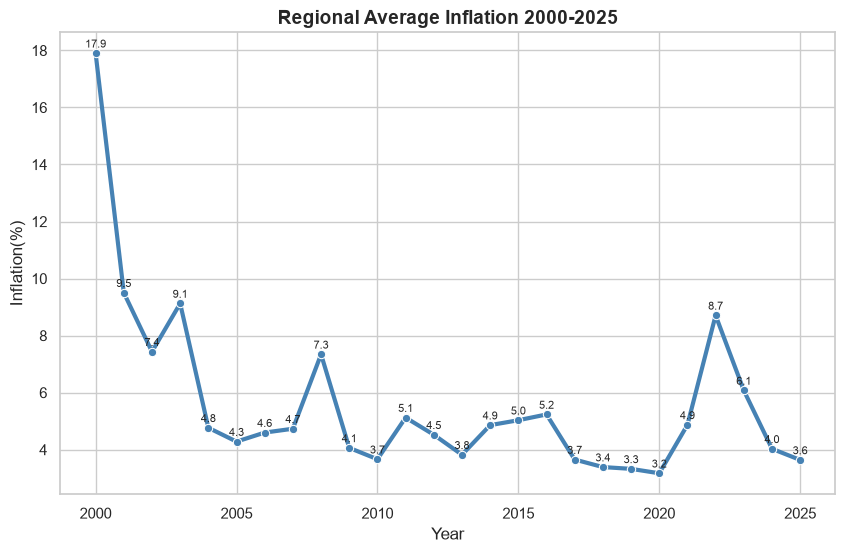

In [32]:
plt.figure(figsize=(10,6))

ax=sns.lineplot(
    data=regional_avg,
    x="year",
    y="inflation",
    linewidth=3,
    marker="o",
    color="steelblue"
)

#etiquetas 

for x, y in zip(
    regional_avg["year"],
    regional_avg["inflation"]
):
    ax.text(
        x,
        y+0.2,
        f"{y:.1f}",
        ha="center",
        fontsize=8
    )
    
plt.title(
    "Regional Average Inflation 2000-2025",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Year")
plt.ylabel("Inflation(%)")

plt.tight_layout


plt.savefig(
    "../images/regional_inflation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

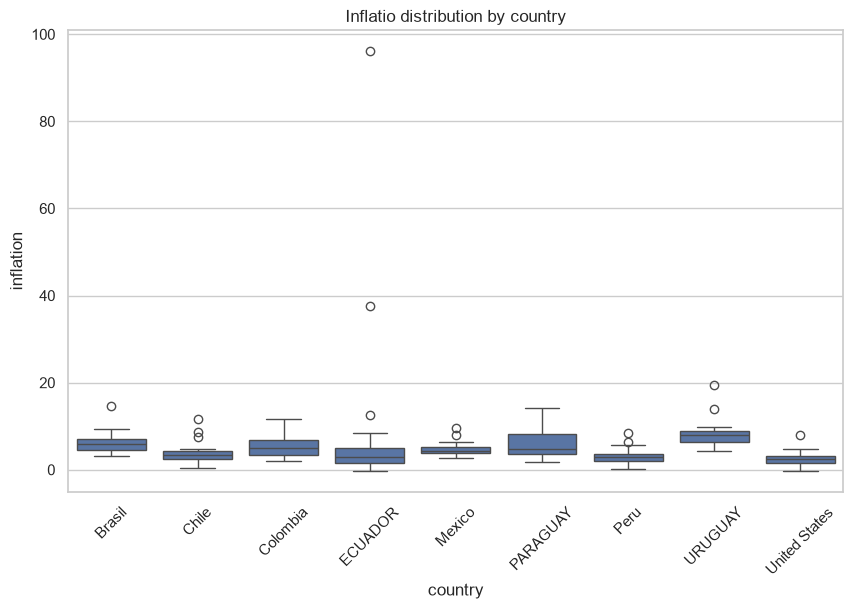

In [34]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=inflation_clean, 
    x="country",
    y="inflation"
)

plt.xticks(rotation=45)

plt.title("Inflatio distribution by country")

plt.show()

In [36]:
Q1 = inflation_clean["inflation"].quantile(0.25)

Q3 = inflation_clean["inflation"].quantile(0.75)

IQR = Q3 - Q1

print(Q1)
print(Q3)
print(IQR)


2.82617111885407
6.59718509985963
3.7710139810055603


In [38]:
outliers = inflation_clean[
(inflation_clean["inflation"] < Q1 - 1.5 * IQR)
|
(inflation_clean["inflation"] > Q3 + 1.5 * IQR)
]

outliers.sort_values(
"inflation",
ascending=False
)

,country,year,inflation
103,ECUADOR,2000,96.096376
102,ECUADOR,2001,37.676745
204,URUGUAY,2003,19.379730
22,Brasil,2003,14.714920
152,PARAGUAY,2003,14.236797
205,URUGUAY,2002,13.972473
101,ECUADOR,2002,12.483598


The Ecuadorian inflation spike observed in 2000 was retained in the dataset because it represents a valid economic event rather than a data quality issue.


In [39]:
#Promedio de latam sin Ecuador

latam_no_ecuador = latam_data[
latam_data["country"] != "ECUADOR"
]

regional_no_ec = (
latam_no_ecuador
.groupby("year")["inflation"]
.mean()
.reset_index()
)

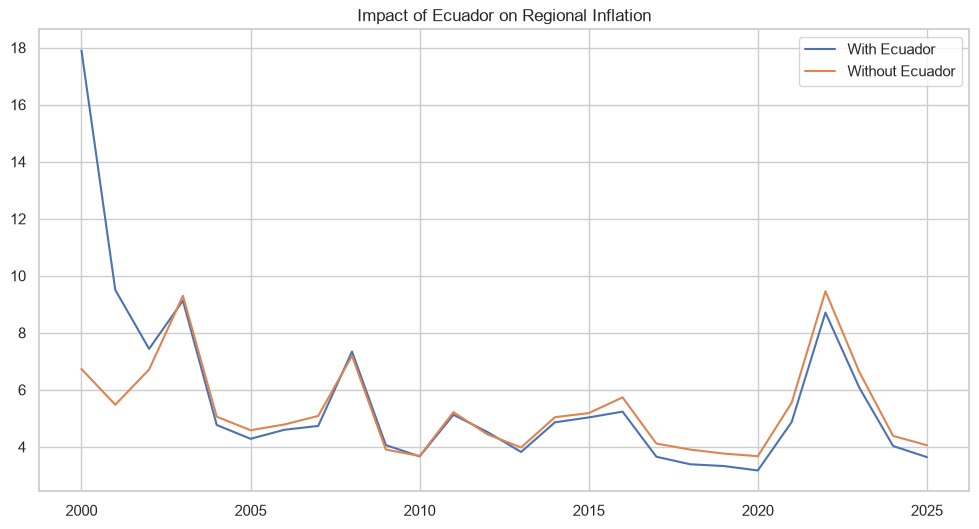

In [40]:
plt.figure(figsize=(12,6))

plt.plot(
regional_avg["year"],
regional_avg["inflation"],
label="With Ecuador"
)

plt.plot(
regional_no_ec["year"],
regional_no_ec["inflation"],
label="Without Ecuador"
)

plt.legend()

plt.title(
"Impact of Ecuador on Regional Inflation"
)

plt.show()